# Exercício 6 · Bootstrap na prática: a fila da Cuida

**Disciplina 4 · Testes de Hipótese e Experimentação · Pós-graduação em Ciência de Dados e IA · UNIPDS**

**GABARITO** · com prompts, código e leituras comentadas.

## O contexto

A **Cuida** é um app de telemedicina. O paciente abre o app, descreve os sintomas numa triagem e entra numa fila até ser atendido por um médico em videochamada.

O time de Produto criou uma **triagem nova**, que faz mais perguntas no início e direciona o paciente para o médico certo. Para testar, os pacientes foram **sorteados**: metade passou pela triagem atual e metade pela nova.

O problema: tempo de espera é uma métrica muito assimétrica. A maioria espera poucos minutos, alguns esperam horas. E duas das perguntas do time não são sobre a média: são sobre a **mediana** e sobre o **percentil 90**, que não têm fórmula simples de intervalo de confiança. É trabalho para o **bootstrap**.

| Parte | Pergunta | Arquivo | Estatística |
|:---|:---|:---|:---|
| 1 | Quanto tempo o paciente típico espera hoje? A meta de 30 min é cumprida? | `espera_triagem.csv` | Mediana e percentil 90 de um grupo |
| 2 | A triagem nova reduz a espera do paciente típico? | `espera_triagem.csv` | Diferença das medianas |
| 3 | A triagem nova melhora o SLA (os 10% que mais esperam)? | `espera_triagem.csv` | Diferença dos percentis 90 |
| 4 | A triagem nova resolve mais consultas de primeira? | `consultas_resolucao.csv` | Taxa por consulta, com sorteio por paciente |

**Os dados**

`espera_triagem.csv`: uma linha por paciente sorteado.

| Coluna | Descrição |
|:---|:---|
| `paciente_id` | Identificador do paciente |
| `triagem` | `atual` ou `nova` |
| `espera_min` | Minutos entre o fim da triagem e o início da videochamada |

`consultas_resolucao.csv`: uma linha por **consulta**, durante um mês. Um mesmo paciente pode ter várias consultas.

| Coluna | Descrição |
|:---|:---|
| `consulta_id` | Identificador da consulta |
| `paciente_id` | Paciente que fez a consulta (a unidade sorteada) |
| `triagem` | `atual` ou `nova` |
| `resolvida` | 1 se o problema foi resolvido nessa consulta, sem precisar de retorno; 0 caso contrário |

### Como usar este gabarito

Cada passo tem o **prompt** usado, o código gerado e a **leitura** do resultado. Os prompts são um exemplo: o importante é que digam **o que** a análise precisa fazer, não **como** codificar. **Todos os intervalos são de 95%, e todos os bootstraps usam 5.000 reamostras e semente 42**, para os números baterem com os do gabarito.

## Parte 0 · Preparação

**Prompt para a IA**

> Vou fazer análises com bootstrap em Python. Prepare o ambiente com as bibliotecas que vamos usar para manipular dados, fazer gráficos e fazer estatística. Use funções prontas sempre que possível e escreva um código simples, para iniciantes. Guarde numa variável o número de reamostras do bootstrap: 5.000.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

N_REAMOSTRAS = 5000

## Parte 1 · O retrato da espera hoje

Antes de comparar as triagens, olhe só o grupo **atual**. A Cuida promete no app que **90% dos pacientes são atendidos em até 30 minutos**. Em linguagem estatística: o percentil 90 da espera deveria ser de no máximo 30 min.

**A receita do bootstrap.** (1) Sorteie, com reposição, uma amostra do mesmo tamanho da original; (2) calcule nela a estatística que interessa; (3) repita milhares de vezes; (4) os percentis 2,5 e 97,5 dessas estatísticas formam o IC de 95%. Serve para qualquer estatística, inclusive as que não têm fórmula.

**Prompt para a IA**

> Leia o arquivo espera_triagem.csv e mostre as primeiras linhas. Para cada triagem, mostre as estatísticas descritivas da espera em minutos, com os percentis 25, 50, 75 e 90. Separe as esperas da triagem atual e da nova em duas variáveis. Faça um histograma da espera na triagem atual com a média e a mediana marcadas.

  paciente_id triagem  espera_min
0       P0284    nova         6.0
1       P0370    nova         8.5
2       P0208   atual        27.7
3       P0301    nova        13.3
4       P0430    nova        66.4

         count  mean   std  min   25%   50%   75%   90%    max
triagem                                                       
atual    220.0  22.1  14.3  2.3  12.5  19.2  27.2  38.8  101.8
nova     220.0  23.4  32.8  2.6   9.3  13.8  21.2  36.4  194.4


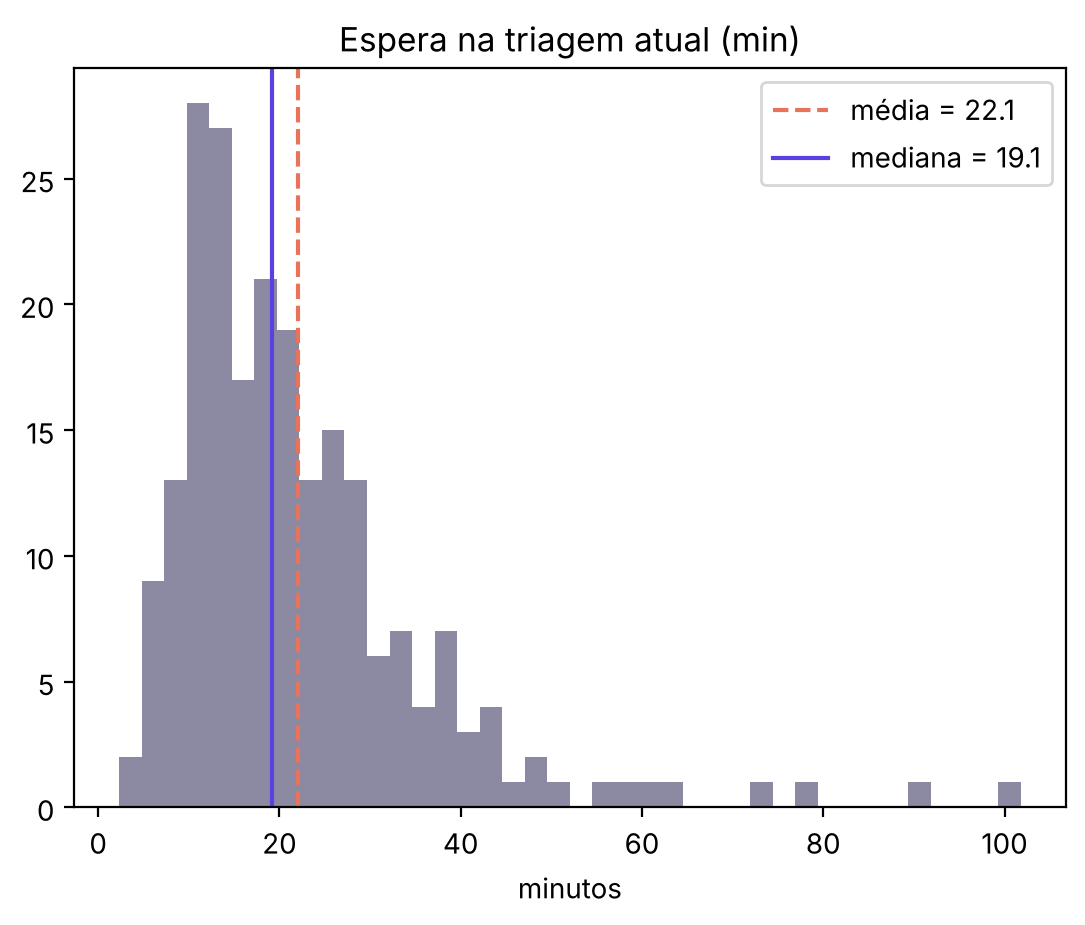

In [2]:
esp = pd.read_csv("espera_triagem.csv")
print(esp.head())
print()
print(esp.groupby("triagem")["espera_min"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))

atual = esp.loc[esp["triagem"] == "atual", "espera_min"].values
nova = esp.loc[esp["triagem"] == "nova", "espera_min"].values

plt.hist(atual, bins=40, color="#8C89A3")
plt.axvline(np.mean(atual), color="#E8735A", linestyle="--", label=f"média = {np.mean(atual):.1f}")
plt.axvline(np.median(atual), color="#5B3FE0", label=f"mediana = {np.median(atual):.1f}")
plt.title("Espera na triagem atual (min)")
plt.xlabel("minutos")
plt.legend()
plt.show()

> **Leitura.** São 220 pacientes em cada triagem. Na atual, a espera é assimétrica: a maioria espera entre 12 e 27 minutos (quartis), mas a cauda vai até 102 min. Por isso a média (22,1) fica acima da mediana (19,2): poucos pacientes com espera longa puxam a média para a direita. Na triagem nova, o desvio-padrão é mais que o dobro (32,8 contra 14,3) e a máxima passa de 3 horas. Guarde isso para a Parte 2.

**Prompt para a IA**

> Na triagem atual, faça o bootstrap da mediana da espera: sorteie, com reposição, uma amostra do mesmo tamanho, calcule a mediana e repita 5.000 vezes (semente 42). Mostre a mediana observada e o IC de 95% pelos percentis 2,5 e 97,5. Para comparar, mostre também a média com o IC de 95% pela distribuição t. Faça um histograma das 5.000 medianas com o intervalo marcado.

Mediana observada: 19.1 min · IC 95% (bootstrap): 17.2 a 20.3
Média observada:   22.1 min · IC 95% (t):         20.2 a 24.0


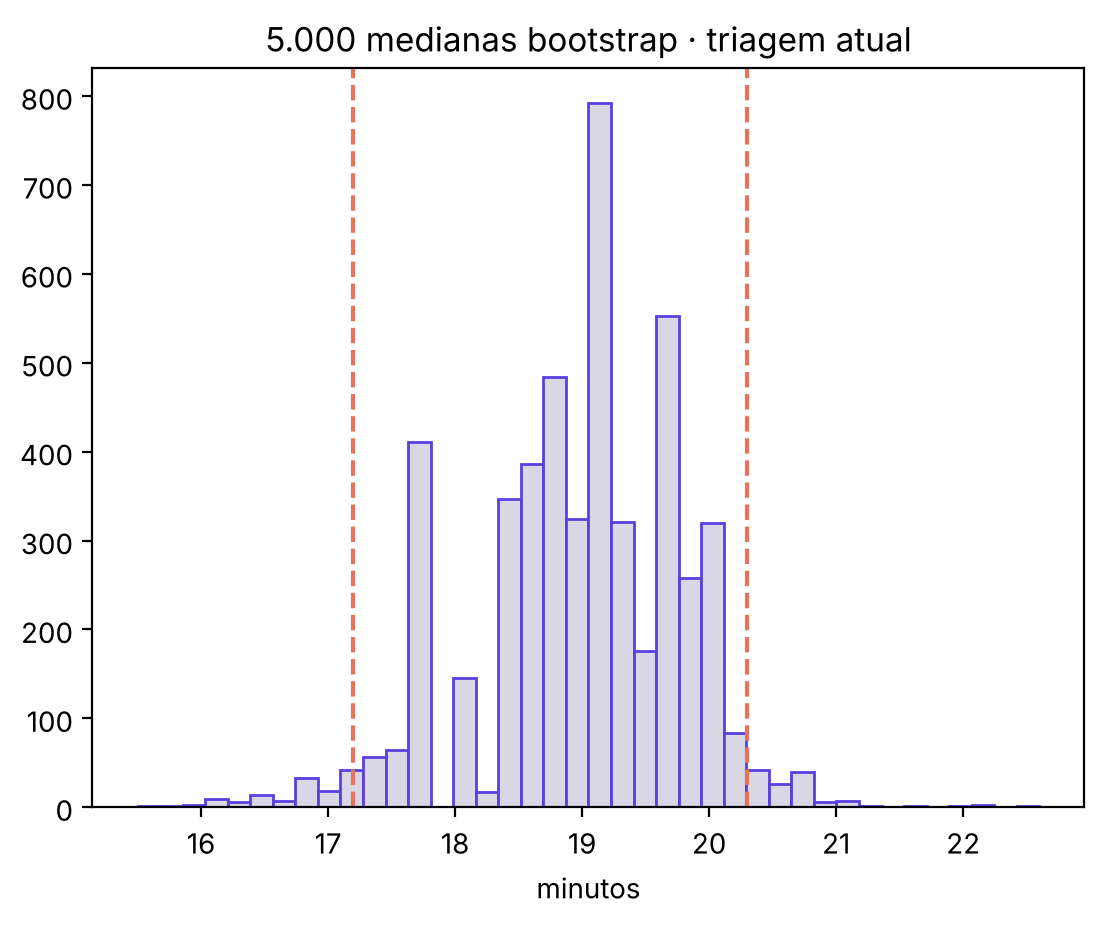

In [3]:
rng = np.random.default_rng(42)

medianas = []
for _ in range(N_REAMOSTRAS):
    amostra = rng.choice(atual, size=len(atual), replace=True)
    medianas.append(np.median(amostra))
medianas = np.array(medianas)

ic_med = np.percentile(medianas, [2.5, 97.5])
print(f"Mediana observada: {np.median(atual):.1f} min · IC 95% (bootstrap): {ic_med[0]:.1f} a {ic_med[1]:.1f}")

ic_t = stats.t.interval(0.95, df=len(atual) - 1, loc=np.mean(atual), scale=stats.sem(atual))
print(f"Média observada:   {np.mean(atual):.1f} min · IC 95% (t):         {ic_t[0]:.1f} a {ic_t[1]:.1f}")

plt.hist(medianas, bins=40, color="#D9D6E6", edgecolor="#5B3FE0")
for x in ic_med:
    plt.axvline(x, color="#E8735A", linestyle="--")
plt.title("5.000 medianas bootstrap · triagem atual")
plt.xlabel("minutos")
plt.show()

> **Leitura.** O paciente típico da triagem atual espera **19,1 minutos**, e o IC de 95% vai de **17,2 a 20,3 min**. Repare que o intervalo não é simétrico em torno de 19,1: o bootstrap não força simetria, ele mostra o formato que os dados permitem. Repare também que o histograma das medianas é "dentado", com poucos valores possíveis: a mediana de uma amostra é sempre um dos valores da amostra (ou a média de dois deles).
>
> A média tem IC de 20,2 a 24,0 min, e os dois intervalos nem se cruzam. Não há contradição: **média e mediana são parâmetros diferentes**. Numa distribuição assimétrica à direita, a média é maior que a mediana. A pergunta "quanto espera o paciente típico" é sobre a mediana.

**Prompt para a IA**

> Ainda na triagem atual, faça o mesmo bootstrap para o percentil 90 da espera (semente 42) e mostre o percentil 90 observado e o IC de 95%. Mostre também a porcentagem de pacientes atendidos em até 30 minutos.

In [4]:
rng = np.random.default_rng(42)

p90s = []
for _ in range(N_REAMOSTRAS):
    amostra = rng.choice(atual, size=len(atual), replace=True)
    p90s.append(np.percentile(amostra, 90))
p90s = np.array(p90s)

ic_p90 = np.percentile(p90s, [2.5, 97.5])
print(f"Percentil 90 observado: {np.percentile(atual, 90):.1f} min · IC 95% (bootstrap): {ic_p90[0]:.1f} a {ic_p90[1]:.1f}")
print(f"Pacientes atendidos em até 30 min: {np.mean(atual <= 30):.1%}")

Percentil 90 observado: 38.8 min · IC 95% (bootstrap): 33.7 a 42.2
Pacientes atendidos em até 30 min: 80.9%


> **Leitura.** O percentil 90 é **38,8 min**, com IC de **33,7 a 42,2 min**. O intervalo inteiro está acima dos 30 minutos prometidos: a meta **não é cumprida**, e não é por acaso. Na prática, só 80,9% dos pacientes são atendidos em até 30 min, e não 90%.
>
> Esse é o tipo de pergunta em que o bootstrap brilha: não existe uma fórmula de livro simples para o IC de um percentil, e o bootstrap resolve com as mesmas quatro linhas de código da mediana.

## Parte 2 · A triagem nova reduz a espera do paciente típico?

- **Parâmetro:** diferença das medianas, nova − atual.
- **Bootstrap para dois grupos:** reamostre **cada grupo separadamente**, com o tamanho dele, e calcule a diferença em cada rodada. O sorteio do experimento separou os grupos; a reamostragem respeita essa separação.

**Prompt para a IA**

> Faça o bootstrap da diferença das medianas da espera (nova menos atual): em cada rodada, sorteie com reposição cada grupo separadamente, com o tamanho dele, e calcule a diferença das medianas. Repita 5.000 vezes (semente 42). Mostre a diferença observada, o IC de 95% e um histograma das diferenças com o intervalo e o zero marcados.

Diferença das medianas (nova − atual): -5.3 min · IC 95%: -7.1 a -2.7


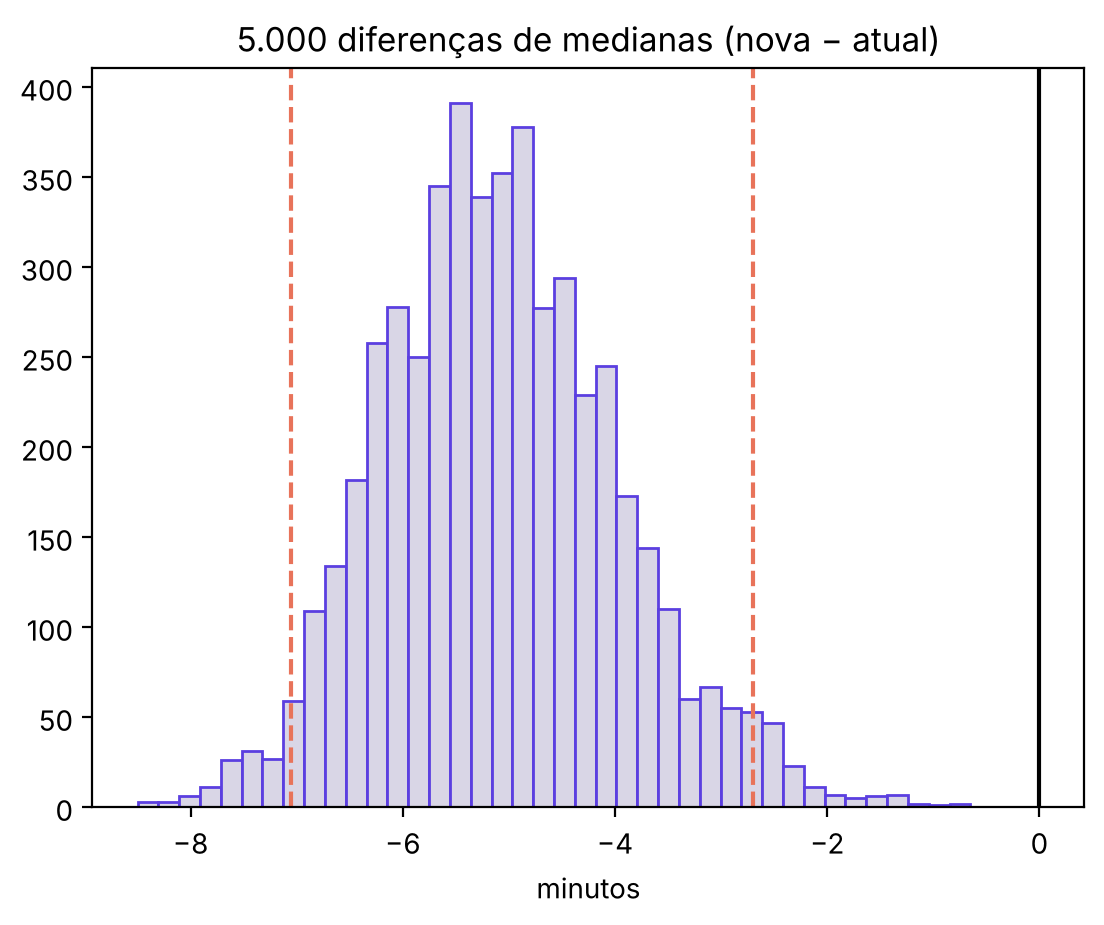

In [5]:
rng = np.random.default_rng(42)

dif_med = []
for _ in range(N_REAMOSTRAS):
    a = rng.choice(atual, size=len(atual), replace=True)
    n = rng.choice(nova, size=len(nova), replace=True)
    dif_med.append(np.median(n) - np.median(a))
dif_med = np.array(dif_med)

obs = np.median(nova) - np.median(atual)
ic = np.percentile(dif_med, [2.5, 97.5])
print(f"Diferença das medianas (nova − atual): {obs:+.1f} min · IC 95%: {ic[0]:.1f} a {ic[1]:.1f}")

plt.hist(dif_med, bins=40, color="#D9D6E6", edgecolor="#5B3FE0")
for x in ic:
    plt.axvline(x, color="#E8735A", linestyle="--")
plt.axvline(0, color="black")
plt.title("5.000 diferenças de medianas (nova − atual)")
plt.xlabel("minutos")
plt.show()

> **Leitura.** A mediana da espera caiu **5,3 minutos** com a triagem nova, e o IC de 95% vai de **−7,1 a −2,7 min**. O intervalo inteiro fica abaixo de zero: o paciente típico espera, plausivelmente, de 3 a 7 minutos a menos com a triagem nova.

**Prompt para a IA**

> Para comparar, faça o teste t de Welch para a diferença das médias (nova menos atual) e mostre a diferença, o p-valor e o IC de 95%. Conte também quantos pacientes de cada triagem esperaram mais de 60 minutos.

In [6]:
welch = stats.ttest_ind(nova, atual, equal_var=False)
ic = welch.confidence_interval()
print(f"Diferença das médias (nova − atual): {nova.mean() - atual.mean():+.1f} min")
print(f"t de Welch: p = {welch.pvalue:.2f} · IC 95%: {ic.low:.1f} a {ic.high:.1f} min")
print()
print(f"Pacientes da triagem nova com mais de 60 min de espera: {np.sum(nova > 60)} de {len(nova)}")
print(f"Pacientes da triagem atual com mais de 60 min de espera: {np.sum(atual > 60)} de {len(atual)}")

Diferença das médias (nova − atual): +1.3 min
t de Welch: p = 0.59 · IC 95%: -3.4 a 6.1 min

Pacientes da triagem nova com mais de 60 min de espera: 15 de 220
Pacientes da triagem atual com mais de 60 min de espera: 5 de 220


> **Leitura.** Pela média, o resultado é o oposto: **+1,3 min**, com p = 0,59 e IC de −3,4 a +6,1 min. Inconclusivo, e com a estimativa pontual apontando para piora.
>
> A contagem explica: 15 pacientes da triagem nova esperaram mais de 1 hora, contra 5 da atual. A triagem nova encaminha os casos complexos para um especialista, e esses pacientes esperam muito. São poucos, mas cada um pesa muito na média e infla a variância (por isso o IC é tão largo).
>
> **As duas análises não se contradizem; elas respondem perguntas diferentes.** A mediana diz que o paciente típico ficou mais bem servido. A média mistura essa melhora com a piora de um grupo pequeno. As duas informações importam para a decisão.

## Parte 3 · O SLA: e os 10% que mais esperam?

A meta do app fala do percentil 90, não da mediana. Uma triagem pode melhorar o paciente típico e piorar a cauda, ou o contrário.

- **Parâmetro:** diferença dos percentis 90, nova − atual.

**Prompt para a IA**

> Faça o bootstrap da diferença dos percentis 90 da espera (nova menos atual), do mesmo jeito da parte anterior (semente 42). Mostre o percentil 90 de cada triagem, a diferença observada, o IC de 95% e um histograma das diferenças.

P90 atual: 38.8 · P90 nova: 36.4
Diferença dos P90 (nova − atual): -2.4 min · IC 95%: -9.8 a 27.4


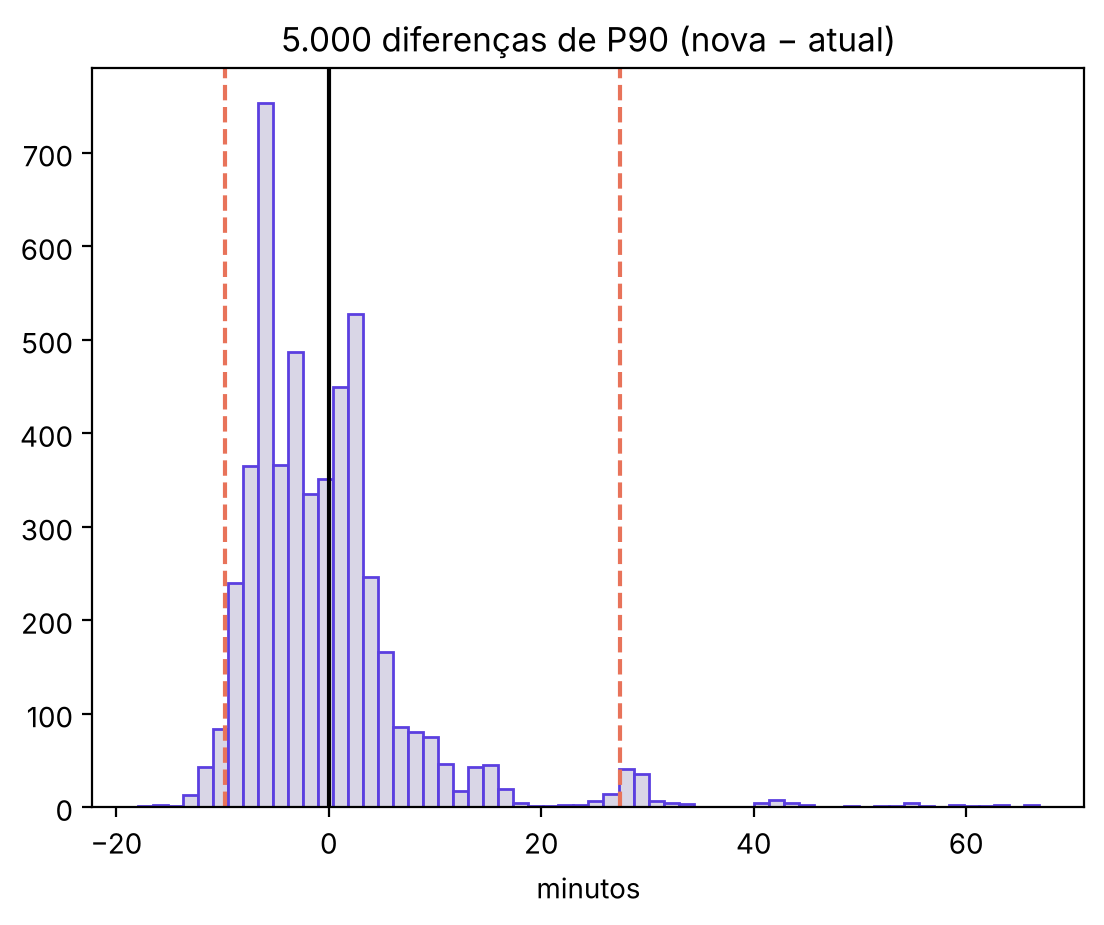

In [7]:
rng = np.random.default_rng(42)

dif_p90 = []
for _ in range(N_REAMOSTRAS):
    a = rng.choice(atual, size=len(atual), replace=True)
    n = rng.choice(nova, size=len(nova), replace=True)
    dif_p90.append(np.percentile(n, 90) - np.percentile(a, 90))
dif_p90 = np.array(dif_p90)

obs = np.percentile(nova, 90) - np.percentile(atual, 90)
ic = np.percentile(dif_p90, [2.5, 97.5])
print(f"P90 atual: {np.percentile(atual, 90):.1f} · P90 nova: {np.percentile(nova, 90):.1f}")
print(f"Diferença dos P90 (nova − atual): {obs:+.1f} min · IC 95%: {ic[0]:.1f} a {ic[1]:.1f}")

plt.hist(dif_p90, bins=60, color="#D9D6E6", edgecolor="#5B3FE0")
for x in ic:
    plt.axvline(x, color="#E8735A", linestyle="--")
plt.axvline(0, color="black")
plt.title("5.000 diferenças de P90 (nova − atual)")
plt.xlabel("minutos")
plt.show()

> **Leitura.** O percentil 90 caiu de 38,8 para 36,4 min (−2,4 min), mas o IC vai de **−9,8 a +27,4 min**: enorme e contendo o zero. **Inconclusivo.** Com estes dados, não dá para dizer se a triagem nova melhora, mantém ou piora o SLA. O histograma das diferenças é estranho, cheio de saltos e com uma cauda longa à direita.
>
> Compare com a Parte 2: os mesmos 220 pacientes por grupo deram um IC de 4,4 minutos de largura para a mediana e de 37 minutos para o percentil 90. Estimar a cauda é muito mais difícil que estimar o meio: no percentil 90, só uns 22 pacientes de cada grupo estão "acima" do valor, e qualquer um deles entrando ou saindo da reamostra muda muito o resultado.

**Prompt para a IA**

> Mostre os percentis 80, 85, 88, 90, 92, 94 e 96 da espera na triagem nova.

In [8]:
print("Percentis da triagem nova:")
for q in [80, 85, 88, 90, 92, 94, 96]:
    print(f"  P{q}: {np.percentile(nova, q):6.1f} min")

Percentis da triagem nova:
  P80:   23.7 min
  P85:   29.4 min
  P88:   32.6 min
  P90:   36.4 min
  P92:   42.6 min
  P94:   66.4 min
  P96:  105.7 min


> **Leitura.** A tabela mostra o porquê: na triagem nova, os percentis andam devagar até o 90 (de 23,7 a 36,4 min) e depois **saltam** (66 min no P94, 106 min no P96). O percentil 90 está bem na beira do grupo dos casos encaminhados ao especialista (cerca de 6% dos pacientes). Em cada reamostra, esse grupo fica um pouco maior ou menor, e o P90 pula de ~35 para ~60 min. Daí o histograma com saltos e o IC enorme.
>
> **Lição:** o bootstrap sempre devolve um número, mas não faz milagre. Percentis extremos, com poucas observações na cauda, e distribuições com "degraus" geram ICs instáveis. Nesses casos, é melhor medir a cauda de outro jeito, por exemplo a **proporção de pacientes que esperam mais de 30 min** (uma proporção tem IC de fórmula e é mais estável), ou coletar mais dados.

## Parte 4 · Resolução na primeira consulta: quem foi sorteado?

A métrica é a **taxa de resolução**: consultas resolvidas sem retorno ÷ total de consultas. Mas o sorteio foi feito por **paciente**, e um mesmo paciente faz várias consultas. Consultas do mesmo paciente se parecem: quem tem um problema simples resolve quase todas; quem tem um caso difícil volta várias vezes.

Isso muda o bootstrap: a reamostragem precisa imitar o sorteio. Se a unidade sorteada é o paciente, reamostramos **pacientes**, levando junto **todas as consultas** de cada um. É o **bootstrap por cluster**.

**Prompt para a IA**

> Leia o arquivo consultas_resolucao.csv e mostre as primeiras linhas. Para cada triagem, mostre o número de consultas, o número de pacientes e a taxa de resolução (média da coluna resolvida). Mostre também as estatísticas descritivas do número de consultas por paciente.

In [9]:
cons = pd.read_csv("consultas_resolucao.csv")
print(cons.head())
print()
resumo = cons.groupby("triagem").agg(consultas=("consulta_id", "count"),
                                     pacientes=("paciente_id", "nunique"),
                                     taxa_resolucao=("resolvida", "mean"))
print(resumo.round(3))

por_paciente = cons.groupby(["triagem", "paciente_id"])["resolvida"].agg(["count", "mean"])
print()
print("Consultas por paciente:")
print(por_paciente["count"].describe().round(1))

  consulta_id paciente_id triagem  resolvida
0      C00001        A000   atual          0
1      C00002        A001   atual          1
2      C00003        A001   atual          0
3      C00004        A001   atual          0
4      C00005        A002   atual          0

         consultas  pacientes  taxa_resolucao
triagem                                      
atual          461        150           0.560
nova           432        150           0.646

Consultas por paciente:
count    300.0
mean       3.0
std        2.7
min        1.0
25%        1.0
50%        2.0
75%        3.0
max       12.0
Name: count, dtype: float64


> **Leitura.** São 893 consultas de 300 pacientes, 150 sorteados para cada triagem. A taxa de resolução é de **56,0%** na atual e **64,6%** na nova, uma diferença de 8,6 p.p. Cada paciente fez em média 3 consultas, mas a distribuição é desigual: metade fez 1 ou 2, e alguns chegaram a 12. Esses pacientes que voltam muitas vezes pesam muito na taxa por consulta.

**Prompt para a IA**

> Faça um primeiro bootstrap da diferença da taxa de resolução (nova menos atual) reamostrando as consultas de cada grupo, como se fossem independentes (semente 42, 5.000 reamostras). Mostre a diferença observada e o IC de 95%, em pontos percentuais.

In [10]:
rng = np.random.default_rng(42)
res_atual = cons.loc[cons["triagem"] == "atual", "resolvida"].values
res_nova = cons.loc[cons["triagem"] == "nova", "resolvida"].values

dif_ingenuo = []
for _ in range(N_REAMOSTRAS):
    a = rng.choice(res_atual, size=len(res_atual), replace=True)
    n = rng.choice(res_nova, size=len(res_nova), replace=True)
    dif_ingenuo.append(n.mean() - a.mean())
dif_ingenuo = np.array(dif_ingenuo)

obs = res_nova.mean() - res_atual.mean()
ic_ing = np.percentile(dif_ingenuo, [2.5, 97.5])
print(f"Diferença observada (nova − atual): {obs * 100:+.1f} p.p.")
print(f"IC 95% reamostrando CONSULTAS: {ic_ing[0] * 100:+.1f} a {ic_ing[1] * 100:+.1f} p.p.")

Diferença observada (nova − atual): +8.6 p.p.
IC 95% reamostrando CONSULTAS: +2.1 a +15.1 p.p.


> **Leitura.** Reamostrando consultas, o IC vai de **+2,1 a +15,1 p.p.** Exclui o zero: pela análise "ingênua", a triagem nova resolve mais.

**Prompt para a IA**

> Agora faça o bootstrap por cluster: em cada rodada, sorteie com reposição os pacientes de cada grupo, levando todas as consultas de cada paciente sorteado, e calcule a taxa de resolução como consultas resolvidas divididas pelo total de consultas. Repita 5.000 vezes (semente 42) e mostre o IC de 95% da diferença (nova menos atual), em p.p. Compare a largura dos dois intervalos e mostre os dois histogramas sobrepostos.

IC 95% reamostrando PACIENTES: -1.4 a +18.1 p.p.
Largura: consultas = 13.0 p.p. · pacientes = 19.5 p.p.


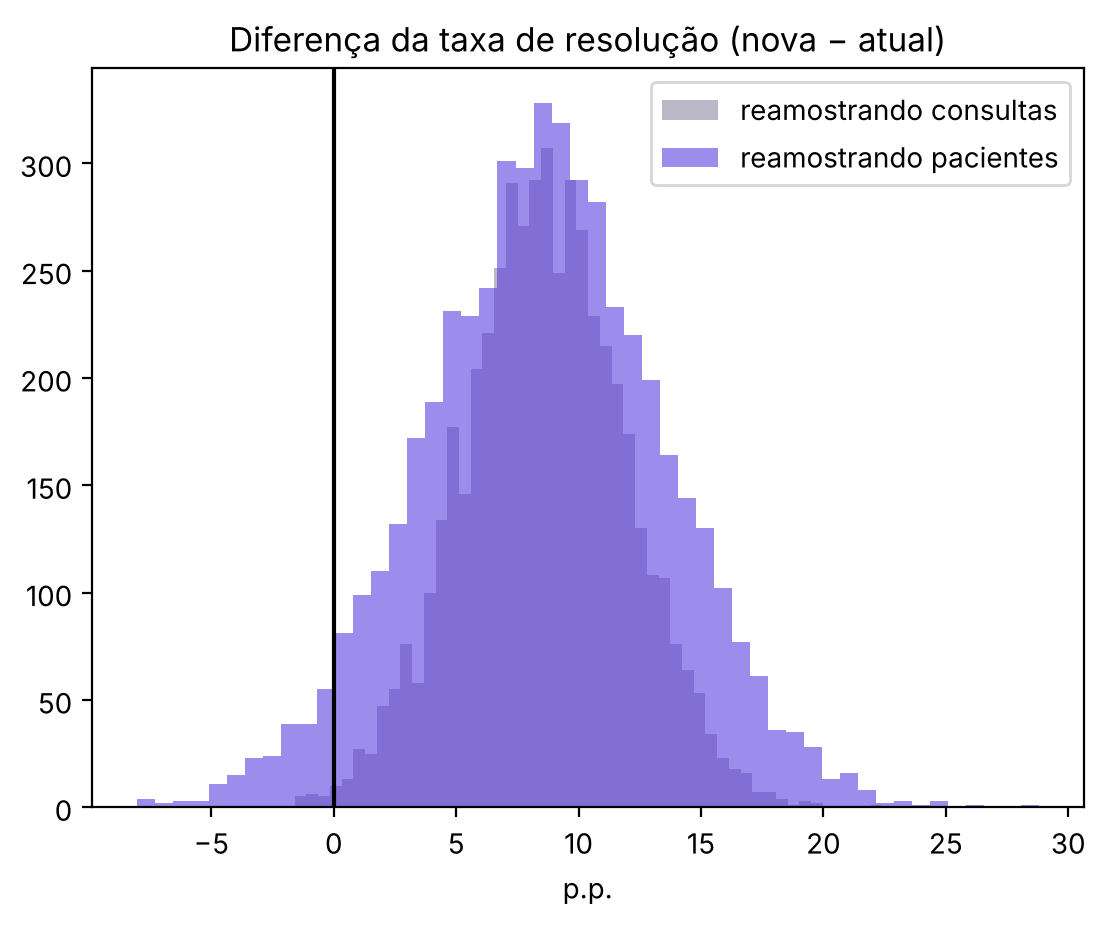

In [11]:
rng = np.random.default_rng(42)

# uma linha por paciente: consultas resolvidas e total de consultas
pac_atual = cons[cons["triagem"] == "atual"].groupby("paciente_id")["resolvida"].agg(["sum", "count"]).values
pac_nova = cons[cons["triagem"] == "nova"].groupby("paciente_id")["resolvida"].agg(["sum", "count"]).values

def taxa_reamostrada(pacientes):
    idx = rng.integers(0, len(pacientes), size=len(pacientes))   # sorteia pacientes com reposição
    amostra = pacientes[idx]
    return amostra[:, 0].sum() / amostra[:, 1].sum()             # resolvidas ÷ consultas

dif_cluster = np.array([taxa_reamostrada(pac_nova) - taxa_reamostrada(pac_atual) for _ in range(N_REAMOSTRAS)])

ic_clu = np.percentile(dif_cluster, [2.5, 97.5])
print(f"IC 95% reamostrando PACIENTES: {ic_clu[0] * 100:+.1f} a {ic_clu[1] * 100:+.1f} p.p.")
print(f"Largura: consultas = {(ic_ing[1] - ic_ing[0]) * 100:.1f} p.p. · pacientes = {(ic_clu[1] - ic_clu[0]) * 100:.1f} p.p.")

plt.hist(dif_ingenuo * 100, bins=50, alpha=0.6, color="#8C89A3", label="reamostrando consultas")
plt.hist(dif_cluster * 100, bins=50, alpha=0.6, color="#5B3FE0", label="reamostrando pacientes")
plt.axvline(0, color="black")
plt.title("Diferença da taxa de resolução (nova − atual)")
plt.xlabel("p.p.")
plt.legend()
plt.show()

> **Leitura.** Reamostrando pacientes, o IC vai de **−1,4 a +18,1 p.p.**: 50% mais largo, e agora **contendo o zero**. A conclusão muda: o resultado é **inconclusivo**.
>
> **Qual está certo?** O por paciente. As consultas de um mesmo paciente não são independentes: um paciente com um caso difícil volta várias vezes e acumula vários "não resolvido". Na prática, temos 150 pacientes por grupo, e não 450 consultas independentes. Reamostrar consultas finge que temos mais informação do que temos, e o IC fica estreito demais. Com ele, a Cuida teria lançado a triagem achando que ela resolve mais, com um risco de falso positivo bem acima dos 5% combinados.
>
> **Regra:** reamostre a unidade que foi sorteada. Aqui, o paciente.

## Parte 5 · As recomendações

| Pergunta | Recomendação |
|:---|:---|
| Espera do paciente típico | **A triagem nova melhora.** A mediana caiu 5,3 min (IC de −7,1 a −2,7 min). |
| Meta de 30 min (P90) | **A meta não é cumprida hoje** (P90 de 38,8 min, IC de 33,7 a 42,2). Sobre a triagem nova, os dados **não permitem concluir** (IC da diferença de −9,8 a +27,4 min). Acompanhar a proporção de pacientes com espera acima de 30 min, que é mais estável. |
| Casos encaminhados ao especialista | **Investigar antes de lançar.** São 15 pacientes com mais de 1 hora de espera na triagem nova, contra 5 na atual. É o que deixa a média e o P90 inconclusivos. |
| Resolução na primeira consulta | **Ainda não dá para afirmar** que a triagem nova resolve mais: o IC por paciente vai de −1,4 a +18,1 p.p. O teste precisa de mais pacientes, não de mais consultas. |

**No geral:** a triagem nova é promissora para o paciente típico, mas não deve ser lançada antes de resolver a fila dos casos encaminhados ao especialista.

### Perguntas para discussão

1. Por que, na Parte 2, a mediana e a média chegam a conclusões diferentes? Qual das duas responde à pergunta do time?
2. Por que o IC do percentil 90 é tão mais largo que o IC da mediana, com os mesmos 220 pacientes?
3. Na Parte 4, por que reamostrar consultas dá um IC mais estreito? Que erro de decisão isso poderia causar?
4. O bootstrap resolve qualquer problema de amostra? Cite uma situação em que ele não ajuda.

**Respostas comentadas**

1. Porque a triagem nova melhora a maioria dos pacientes e piora um grupo pequeno (os encaminhados ao especialista), que espera muito. A mediana olha o paciente do meio e não se importa com o tamanho da cauda; a média soma todos os minutos e é dominada por esses poucos casos. A pergunta "o paciente típico espera menos?" é sobre a mediana. Mas a média avisa que existe um problema na cauda.
2. Porque a estatística depende de poucas observações. A mediana tem ~110 pacientes de cada lado; o P90 tem só ~22 acima dele. E, na triagem nova, o P90 cai bem na fronteira dos casos com espera longa, então pequenas mudanças na reamostra fazem o valor saltar.
3. Porque trata as consultas como independentes, e elas não são: as do mesmo paciente se parecem. O IC fica estreito demais, e o teste rejeita H0 com mais frequência do que os 5% prometidos. O erro seria um **falso positivo** (tipo I): lançar a triagem achando que ela resolve mais, sem evidência suficiente.
4. Não. O bootstrap só reamostra o que está na amostra: se a amostra é viesada (por exemplo, só pacientes de um horário ou de uma região), ele reproduz o viés com muita precisão. Ele também não funciona bem com amostras muito pequenas (com 8 observações, há poucas reamostras diferentes) nem para estatísticas extremas, como o máximo ou percentis muito altos.